# LLM Evaluation Plots (Detailed)

This notebook loads `results.json` and produces summary and breakdown plots.

In [24]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt


In [25]:
def resolve_results_path():
    candidates = [
        Path("results.json"),
        Path("evaluation/llm/results.json"),
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError("results.json not found. Run eval_llm.py first.")

results_path = resolve_results_path()
with results_path.open("r", encoding="utf-8") as handle:
    results = json.load(handle)

summary = results.get("summary", {})
cases = results.get("cases", [])
print(f"Loaded {len(cases)} cases from {results_path}")


Loaded 60 cases from results.json


In [26]:
def group_success_rates(cases):
    stats = defaultdict(lambda: {"success": 0, "total": 0})
    for case in cases:
        category = case.get("category", "unknown")
        stats[category]["total"] += 1
        if case.get("task_success"):
            stats[category]["success"] += 1
    return {
        k: (v["success"] / v["total"] if v["total"] else 0.0)
        for k, v in stats.items()
    }

def compute_clean_robust(cases):
    clean_total = 0
    clean_success = 0
    robust_total = 0
    robust_success = 0
    for case in cases:
        category = case.get("category", "")
        is_robust = "robust" in category
        if is_robust:
            robust_total += 1
            if case.get("task_success"):
                robust_success += 1
        else:
            clean_total += 1
            if case.get("task_success"):
                clean_success += 1
    clean_rate = clean_success / clean_total if clean_total else 0.0
    robust_rate = robust_success / robust_total if robust_total else 0.0
    return clean_rate, robust_rate

clean_rate, robust_rate = compute_clean_robust(cases)


## Overall Metrics

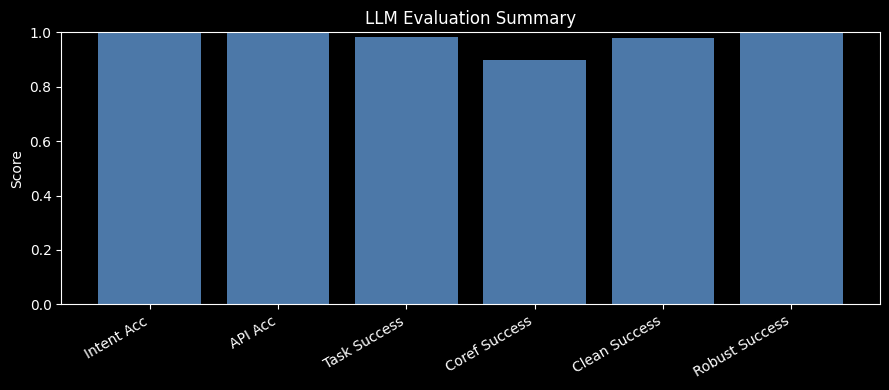

In [27]:
metrics = {
    "Intent Acc": summary.get("intent_accuracy", 0.0),
    "API Acc": summary.get("api_call_accuracy", 0.0),
    "Task Success": summary.get("task_success_rate", 0.0),
    "Coref Success": summary.get("coref_success_rate", 0.0),
    "Clean Success": clean_rate,
    "Robust Success": robust_rate,
}

plt.figure(figsize=(9, 4))
plt.bar(metrics.keys(), metrics.values(), color="#4C78A8")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("LLM Evaluation Summary")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Params vs Body Field Accuracy

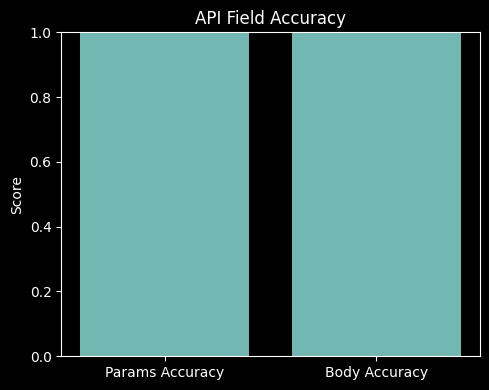

In [28]:
field_metrics = {
    "Params Accuracy": summary.get("params_field_accuracy", 0.0),
    "Body Accuracy": summary.get("body_field_accuracy", 0.0),
}

plt.figure(figsize=(5, 4))
plt.bar(field_metrics.keys(), field_metrics.values(), color="#72B7B2")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("API Field Accuracy")
plt.tight_layout()
plt.show()


## Task Success by Category

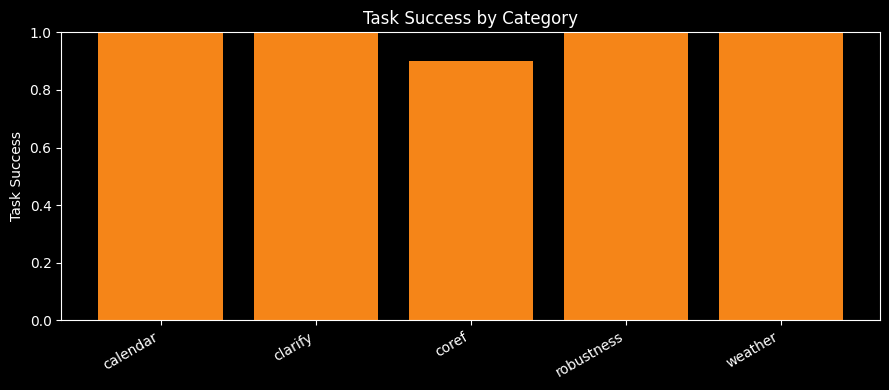

In [29]:
category_rates = group_success_rates(cases)
categories = sorted(category_rates.keys())
rates = [category_rates[c] for c in categories]

plt.figure(figsize=(9, 4))
plt.bar(categories, rates, color="#F58518")
plt.ylim(0, 1)
plt.ylabel("Task Success")
plt.title("Task Success by Category")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Slot Metrics (Precision/Recall/F1)

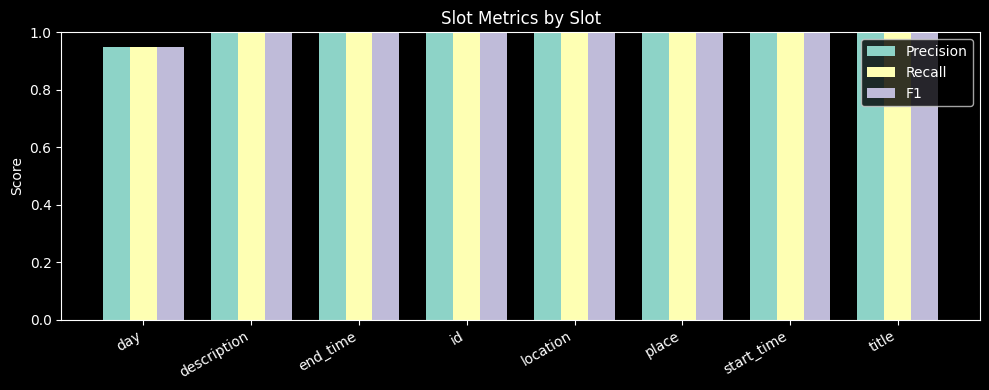

In [30]:
slot_metrics = summary.get("slot_metrics", {})
slots = sorted(slot_metrics.keys())
precision_scores = [slot_metrics[s].get("precision", 0.0) for s in slots]
recall_scores = [slot_metrics[s].get("recall", 0.0) for s in slots]
f1_scores = [slot_metrics[s].get("f1", 0.0) for s in slots]

x = range(len(slots))
width = 0.25

plt.figure(figsize=(10, 4))
plt.bar([i - width for i in x], precision_scores, width=width, label="Precision")
plt.bar(x, recall_scores, width=width, label="Recall")
plt.bar([i + width for i in x], f1_scores, width=width, label="F1")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Slot Metrics by Slot")
plt.xticks(list(x), slots, rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


## Intent Confusion Matrix

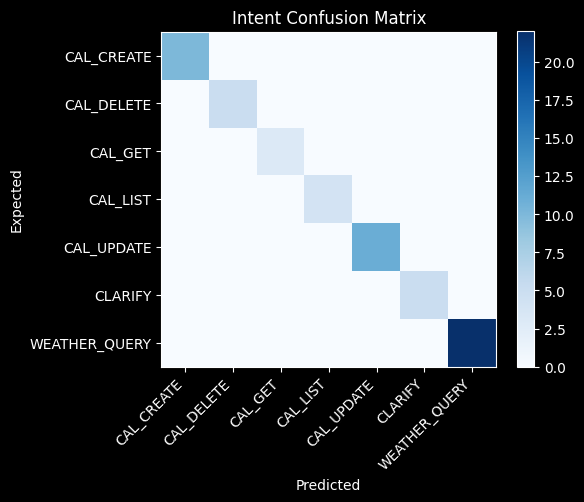

In [31]:
confusion = summary.get("confusion_matrix", [])
if confusion:
    labels = confusion[0][1:]
    matrix = [[int(x) for x in row[1:]] for row in confusion[1:]]

    plt.figure(figsize=(6, 5))
    plt.imshow(matrix, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
    plt.yticks(range(len(labels)), labels)
    plt.title("Intent Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Expected")
    plt.tight_layout()
    plt.show()
else:
    print("No confusion matrix found in results.")
